In [1]:
pip list

Package                       Version
----------------------------- --------------------
absl-py                       2.1.0
affine                        2.4.0
alabaster                     0.7.12
anyio                         4.2.0
argon2-cffi                   21.3.0
argon2-cffi-bindings          21.2.0
arrow                         1.2.3
astroid                       2.14.2
asttokens                     2.0.5
astunparse                    1.6.3
async-lru                     2.0.4
atomicwrites                  1.4.0
attrs                         23.1.0
autopep8                      2.0.4
Babel                         2.11.0
bcrypt                        3.2.0
beautifulsoup4                4.12.2
binaryornot                   0.4.4
black                         24.3.0
bleach                        4.1.0
Brotli                        1.0.9
certifi                       2024.2.2
cffi                          1.16.0
chainer                       7.8.1
chardet                       4.0.0

In [2]:
# needed to open GeoTIFF files
from osgeo import gdal
from osgeo import gdalconst
import tifffile

# needed to create plots
import matplotlib.pyplot as plt
import os
import skimage
# needed to manipulate arrays
import numpy as np

# needed to resize raster and apply HSV <-> RGB color transforms
from skimage.transform import resize
from skimage.color import rgb2hsv, hsv2rgb

In [3]:
# define the file names for RGB and panchromatic (pan) images
filename_rgb = "D:/geoinformatics/MajorProject/Results/tif_results/uint16/patches/uint16RGB/RGB_U16_0_0.tif"
filename_pan = "D:/geoinformatics/MajorProject/Results/tif_results/uint16/patches/uint16PAN/PAN_U16_0_0.tif"

In [4]:
# define constants
figure_border = 5
max_steps = 450

In [5]:
gdal.UseExceptions()

In [6]:
# load the datasets
try:
  dataset_rgb = gdal.Open(filename_rgb)
  dataset_pan = gdal.Open(filename_pan) 
except:
  print('error loading files')

In [7]:
# retrieve metadata
columns = dataset_rgb.RasterXSize
rows = dataset_rgb.RasterYSize

max_pixel = 37383

# get the arrays for Red, Green, Blue and pan images
array_rgb = np.zeros((rows, columns, 3))
array_rgb[:,:,0] = dataset_rgb.GetRasterBand(1).ReadAsArray().astype(float)
array_rgb[:,:,1] = dataset_rgb.GetRasterBand(2).ReadAsArray().astype(float)
array_rgb[:,:,2] = dataset_rgb.GetRasterBand(3).ReadAsArray().astype(float)
array_pan = dataset_pan.GetRasterBand(1).ReadAsArray().astype(float)

print("X size:", columns)
print("Y size:", rows)

X size: 128
Y size: 128


In [8]:
# normalize RGB and pan to 0..1 interval
array_rgb = array_rgb / max_pixel
array_pan = array_pan / max_pixel

print("RGB array is:", array_rgb)
print("PAN array is:", array_pan)

RGB array is: [[[0.30936522 0.29294064 0.29064013]
  [0.3052992  0.28652061 0.28376535]
  [0.30580745 0.28633336 0.28328385]
  ...
  [0.34863441 0.3685365  0.42332076]
  [0.34850066 0.36658374 0.421261  ]
  [0.34759115 0.36663724 0.4213145 ]]

 [[0.30981997 0.29342214 0.29304764]
  [0.30553995 0.28692186 0.28397935]
  [0.30468395 0.2852366  0.28130434]
  ...
  [0.34959741 0.36966001 0.42476527]
  [0.34916941 0.36813525 0.42308001]
  [0.3477784  0.36626274 0.420726  ]]

 [[0.30800096 0.29050638 0.28879437]
  [0.3058342  0.28676136 0.2844341 ]
  [0.3046572  0.28534361 0.28125084]
  ...
  [0.35034641 0.36998101 0.42551427]
  [0.34911591 0.36770725 0.42241126]
  [0.3483134  0.36682449 0.4202445 ]]

 ...

 [[0.31048872 0.30374769 0.30778696]
  [0.32399754 0.32937431 0.3583447 ]
  [0.33076532 0.34368563 0.38667309]
  ...
  [0.29877217 0.28266859 0.27084504]
  [0.29826392 0.28242784 0.27022978]
  [0.29890592 0.28071583 0.27065779]]

 [[0.31431399 0.31051547 0.32295428]
  [0.32485354 0.3287055

In [9]:
# resize all low spatial resolution images
columns = dataset_pan.RasterXSize
rows = dataset_pan.RasterYSize
array_rgb = resize(array_rgb, (rows, columns))

In [10]:
band_order = [3, 2, 1]

for band_num in band_order:
    band = dataset_rgb.GetRasterBand(band_num)
    print(f"Band {band_num}:")
    print(f"  Data Type: {band.DataType}")  # Print data type (e.g., GDT_Byte)
    print(f"  Color Interpretation: {band.GetColorInterpretation()}")  # Color interpretation (e.g., Red, Green, Blue)
    print(f"  Band Shape: {band.ReadAsArray().shape}")  # Print band data shape


Band 3:
  Data Type: 2
  Color Interpretation: 0
  Band Shape: (128, 128)
Band 2:
  Data Type: 2
  Color Interpretation: 0
  Band Shape: (128, 128)
Band 1:
  Data Type: 2
  Color Interpretation: 1
  Band Shape: (128, 128)


In [11]:
for band_num in band_order:
    band = dataset_rgb.GetRasterBand(band_num)
    band_data = band.ReadAsArray()
    print(f"Band {band_num}: Min={band_data.min()}, Max={band_data.max()}")

Band 3: Min=8696, Max=23668
Band 2: Min=9651, Max=21345
Band 1: Min=10813, Max=19734


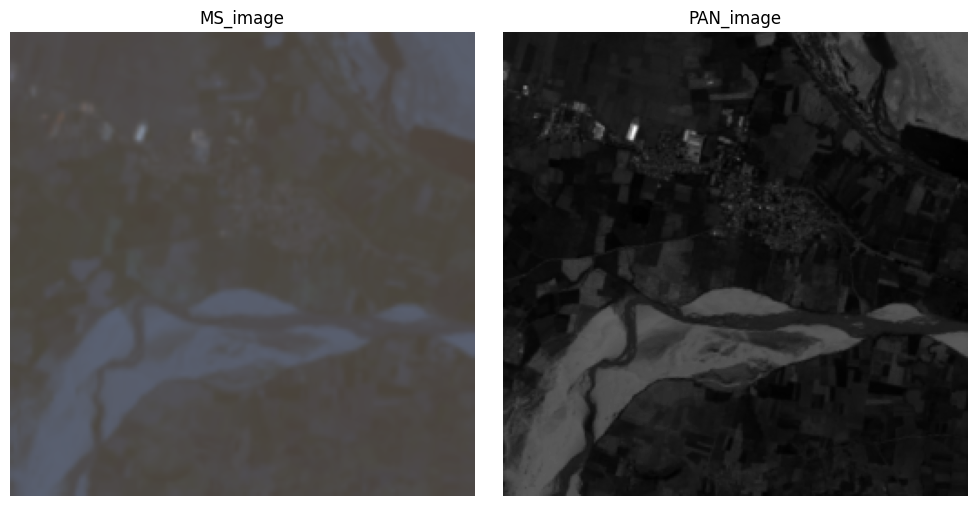

In [12]:
output_fig = plt.figure(figsize=(10, 5))  # Set the figure size

# Plot the MS image
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
plt.imshow(array_rgb)
plt.title('MS_image')  # Set the title for the MS image
plt.axis('off')  # Turn off axis

# Plot the PAN image
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
plt.imshow(array_pan, cmap='gray')
plt.title('PAN_image')  # Set the title for the PAN image
plt.axis('off')  # Turn off axis

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

output_fig.savefig("MS_vs_PAN.png", format='png', dpi=200)

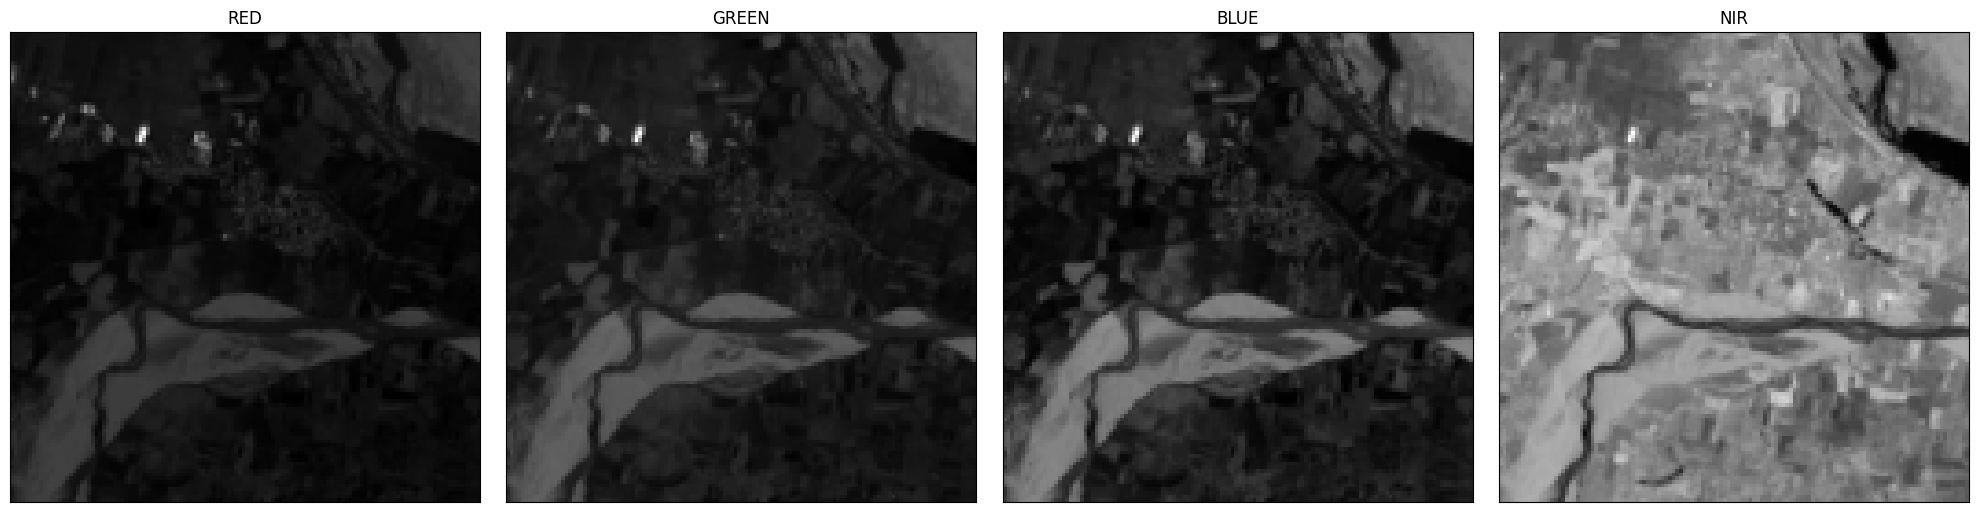

In [14]:
# Loop through and display individual bands
num_bands = dataset_rgb.RasterCount

# Adjust subplot layout for a single row
plt.figure(figsize=(num_bands * 5, 5))  # Adjust figure size based on desired width

for band_number in range(1, num_bands + 1):  # Loop through all bands (1-based indexing)
  band = dataset_rgb.GetRasterBand(band_number)
  band_data = band.ReadAsArray()

  # Optionally normalize data (might be necessary depending on data type)
  # Assuming 8-bit data here
  if band.DataType == gdal.GDT_Byte:
      band_data = band_data.astype(np.float32) / 255

  # Create subplots in a single row
  plt.subplot(1, num_bands, band_number)
  plt.imshow(band_data, cmap='gray')  # Use grayscale for individual bands

  # Set title based on band number with specific titles for R, G, B
  if band_number == 1:
      plt.title("RED")
  elif band_number == 2:
      plt.title("GREEN")
  elif band_number == 3:
      plt.title("BLUE")
  else:
      plt.title("NIR")  # Default title for other bands

  # Remove axis ticks and labels for cleaner individual band view (optional)
  plt.xticks([])
  plt.yticks([])

plt.tight_layout()  # Adjust spacing between subplots
plt.show()
output_fig.savefig("R_G_B_bands.png", format='png', dpi=200)

In [15]:
# make RGB -> HSV transform
array_hsv = rgb2hsv(array_rgb)

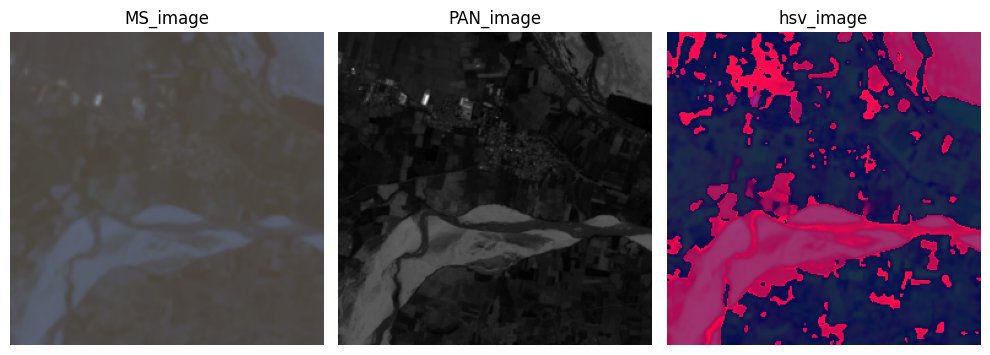

In [16]:
# create figure to display pan Vs Value
output_fig = plt.figure(figsize=(10, 5))  # Set the figure size

# Plot the MS image
plt.subplot(1, 3, 1)  # 1 row, 2 columns, 1st subplot
plt.imshow(array_rgb)
plt.title('MS_image')  # Set the title for the MS image
plt.axis('off')  # Turn off axis

# Plot the PAN image
plt.subplot(1, 3, 2)  # 1 row, 2 columns, 2nd subplot
plt.imshow(array_pan, cmap='gray')
plt.title('PAN_image')  # Set the title for the PAN image
plt.axis('off')  # Turn off axis

# Plot the PAN image
plt.subplot(1, 3, 3)  # 1 row, 2 columns, 2nd subplot
plt.imshow(array_hsv)
plt.title('hsv_image')  # Set the title for the PAN image
plt.axis('off')  # Turn off axis

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

output_fig.savefig("RGB_vs_PAN_HSV.png", format='png', dpi=200)

In [17]:
# create figure to display RGB Vs H, S and V components
output_fig = plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

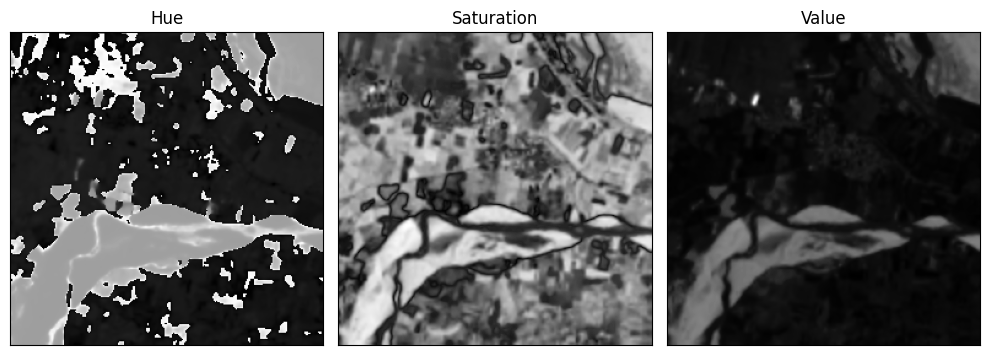

In [18]:
# Adjust subplot layout for a single row
output_fig = plt.figure(figsize=(10, 5))  # Adjust figure size based on desired width

# Loop through and display individual bands
for band_number, title in enumerate(["Hue", "Saturation", "Value"], start=1):  
    band_data = array_hsv[:, :, band_number-1]  # Extract band data
    
    # Create subplots in a single row
    plt.subplot(1, 3, band_number)
    plt.imshow(band_data, cmap='gray')  # Use grayscale for individual bands
    
    # Set title based on band number
    plt.title(title)
    
    # Remove axis ticks and labels for cleaner individual band view (optional)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()  # Adjust spacing between subplots
plt.show()

output_fig.savefig("H_S_V_bands.png", format='png', dpi=200)

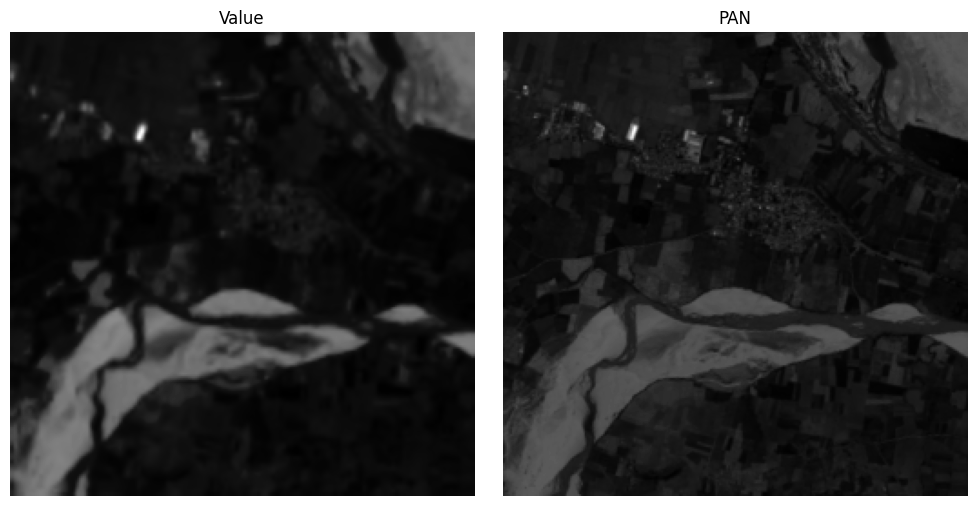

In [19]:
# create figure to display pan Vs Value
output_fig = plt.figure(figsize=(10, 5))  # Set the figure size

# Plot the MS image
plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
plt.imshow(array_hsv[:, :, 2], cmap="gray")
plt.title('Value')  # Set the title for the MS image
plt.axis('off')  # Turn off axis

# Plot the PAN image
plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
plt.imshow(array_pan[:, :], cmap='gray')
plt.title('PAN')  # Set the title for the PAN image
plt.axis('off')  # Turn off axis

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

output_fig.savefig("value_vs_PAN.png", format='png', dpi=200)

In [20]:
# # create animation for changing Value component with pan
# filename_in_animation = "D:/geoinformatics/MajorProject/SpyderCodes/Animation"
# os.makedirs(filename_in_animation, exist_ok=True)
# step = 0
# all_rows = np.linspace(0, rows, max_steps)
# all_columns = np.linspace(0, columns, max_steps)
# for row, column in zip(all_rows, all_columns):
#     array_hsv[0:int(row), 0:int(column), 2] = array_pan[0:int(row), 0:int(column)]
#     array_hsv = array_hsv.astype(np.float16)
#     output_fig = plt.figure(figsize=(9, 5))
#     animation_ax = output_fig.add_subplot(111)
#     animation_img = plt.imshow(array_hsv[:, :, 2], cmap='gray')
#     animation_ax.set_xlim([0 - figure_border, columns + figure_border])
#     animation_ax.set_ylim([rows + figure_border, 0 - figure_border])
#     plt.tight_layout()
#     output_fig.savefig(filename_in_animation + str(step).zfill(6) + ".png", format='png', dpi=200)
#     plt.close()
#     step = step + 1

In [21]:
# make HSV -> RGB transform, replacing Value component by pan
# Reduce precision of arrays to float32 (if memory allows)
array_hsv = array_hsv.astype(np.float32)
array_pan = array_pan.astype(np.float32)

array_hsv[:, :, 2] = array_pan

new_array_rgb = hsv2rgb(array_hsv)

In [22]:
# create figure to display RGB Vs H, S components and panchromatic
output_fig = plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

(261.0, -5.0)

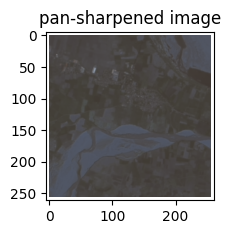

In [23]:
new_rgb_ax = plt.subplot2grid((2, 2), (0, 0))
new_rgb_ax.imshow(new_array_rgb)
new_rgb_ax.set_title("pan-sharpened image")
new_rgb_ax.set_xlim([0 - figure_border, columns + figure_border])
new_rgb_ax.set_ylim([rows + figure_border, 0 - figure_border])

(261.0, -5.0)

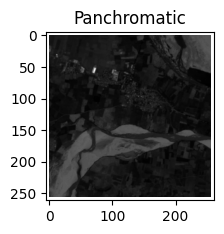

In [24]:
pan_ax = plt.subplot2grid((2, 2), (1, 0))
pan_ax.imshow(array_pan, cmap="gray")
pan_ax.set_title("Panchromatic")
pan_ax.set_xlim([0 - figure_border, columns + figure_border])
pan_ax.set_ylim([rows + figure_border, 0 - figure_border])

(261.0, -5.0)

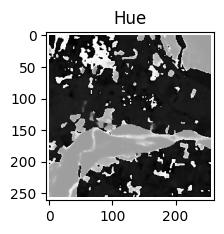

In [25]:
h_ax = plt.subplot2grid((2, 2), (0, 1))
h_ax.imshow(array_hsv[:, :, 0], cmap="gray")
h_ax.set_title("Hue")
h_ax.set_xlim([0 - figure_border, columns + figure_border])
h_ax.set_ylim([rows + figure_border, 0 - figure_border])

(261.0, -5.0)

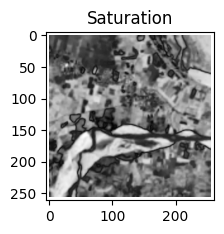

In [26]:
s_ax = plt.subplot2grid((2, 2), (1, 1))
s_ax.imshow(array_hsv[:, :, 1], cmap="gray")
s_ax.set_title("Saturation")
s_ax.set_xlim([0 - figure_border, columns + figure_border])
s_ax.set_ylim([rows + figure_border, 0 - figure_border])

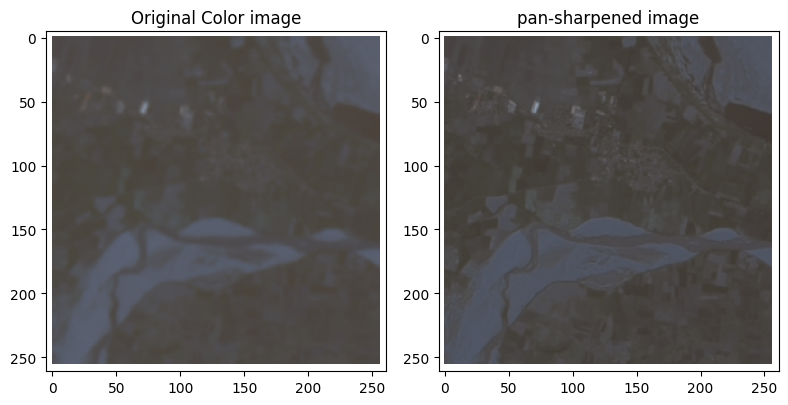

In [28]:
# create figure to display original RGB Vs new RGB
output_fig, (pan_ax, value_ax) = plt.subplots(figsize=(8, 4), ncols=2)
pan_ax.imshow(array_rgb)
pan_ax.set_title("Original Color image")
pan_ax.set_xlim([0 - figure_border, columns + figure_border])
pan_ax.set_ylim([rows + figure_border, 0 - figure_border])
value_ax.imshow(new_array_rgb)
value_ax.set_title("pan-sharpened image")
value_ax.set_xlim([0 - figure_border, columns + figure_border])
value_ax.set_ylim([rows + figure_border, 0 - figure_border])
plt.tight_layout()
output_fig.savefig("original_vs_pan_sharpened.TIF", format='TIF', dpi=200)

In [29]:
plt.tight_layout()
output_fig.savefig("pan_sharpened_vs_hspan.png", format='png', dpi=200)
plt.close()